# Mutual Fund Performance Analysis and Visualization
**CHAITANYA BHARATHI INSTITUTE OF TECHNOLOGY**  
**Department of Information Technology — B.E. IT-1, III Semester, 2026–27**  
**EDAV (22ADC32N) — Course-End Project**

## Objective
Analyze the historical Net Asset Value (NAV) of three sample mutual funds using NumPy, Pandas, Matplotlib, and Seaborn. Calculate descriptive statistics and returns, clean the dataset, compare performance over time, and visualize trends.

## Dataset
File: `sample_mutual_fund_performance_analysis.csv`

The dataset has three columns:
- `Date` — date of the observation
- `Fund_Name` — sample fund identifier (`Fund_A`, `Fund_B`, `Fund_C`)
- `NAV` — illustrative Net Asset Value




## Environment setup
Recommended libraries: `numpy`, `pandas`, `matplotlib`, `seaborn`.

If needed, install them in a notebook cell with:
`%pip install numpy pandas matplotlib seaborn`

## Question-wise guidelines
- **Q1 [CO1, BL3]:** Use NumPy to calculate average, minimum, and maximum NAV for each fund.
- **Q2 [CO2, BL4]:** Use Pandas to compare periodic and cumulative NAV-based returns.
- **Q3 [CO3, BL3]:** Check and handle missing values, duplicates, and invalid NAV values.
- **Q4 [CO4, BL4]:** Group by year and fund to summarize annual-period performance.
- **Q5 [CO5, BL5]:** Create a line plot, bar chart, and heatmap.

Each question includes a concept explanation, code implementation, and conclusion/insight.

## Q0. Load the dataset

**Concept explanation:** Import the required libraries and load the CSV into a Pandas DataFrame. The DataFrame makes it easier to inspect and analyze rows and columns.

**Before running:** Make sure the CSV file is uploaded to the same Colab session as this notebook.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

file_path = "sample_mutual_fund_performance_analysis.csv"
df = pd.read_csv(file_path)

# Convert the Date column to datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
print("Funds:", df["Fund_Name"].dropna().unique().tolist())
print("Date range:", df["Date"].min(), "to", df["Date"].max())
display(df.head(9))

Dataset loaded successfully!
Rows and columns: (72, 3)
Funds: ['Fund_A', 'Fund_B', 'Fund_C']
Date range: 2023-02-01 00:00:00 to 2025-01-01 00:00:00


,Date,Fund_Name,NAV
0,2023-02-01,Fund_A,100.0
1,2023-02-01,Fund_B,50.0
2,2023-02-01,Fund_C,25.0
3,2023-03-01,Fund_A,101.2
4,2023-03-01,Fund_B,50.4
5,2023-03-01,Fund_C,24.8
6,2023-04-01,Fund_A,99.8
7,2023-04-01,Fund_B,51.1
8,2023-04-01,Fund_C,25.3


### Optional: Upload the CSV directly in Google Colab

Use this cell only if you have not already uploaded the CSV through the Files panel. It opens a file chooser.

In [ ]:
# OPTIONAL — run this cell only when you need to upload the CSV from your device.
# from google.colab import files
# uploaded = files.upload()
# Then make sure file_path above matches the uploaded CSV filename.

## Q0.1. Inspect data quality

**Concept explanation:** Before calculating results, inspect the columns, data types, missing values, duplicate rows, and summary statistics. This helps identify problems that may affect the analysis.

In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data type"))

print("\nMissing values by column:")
display(df.isna().sum().to_frame("Missing values"))

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
display(df.describe(include="all"))

Column names:
['Date', 'Fund_Name', 'NAV']

Data types:


,Data type
Date,datetime64[ns]
Fund_Name,object
NAV,float64



Missing values by column:


,Missing values
Date,0
Fund_Name,0
NAV,0



Exact duplicate rows: 0

Summary statistics:


,Date,Fund_Name,NAV
count,72,72,72.000000
unique,NaN,3,NaN
top,NaN,Fund_A,NaN
freq,NaN,24,NaN
mean,2024-01-15 21:00:00,NaN,65.001389
min,2023-02-01 00:00:00,NaN,24.800000
25%,2023-07-24 06:00:00,NaN,30.325000
50%,2024-01-16 12:00:00,NaN,55.900000
75%,2024-07-08 18:00:00,NaN,103.775000
max,2025-01-01 00:00:00,NaN,123.500000


## Data cleaning and preparation

**Concept explanation:** Clean the dataset carefully before analysis. Convert NAV to numeric, parse dates, remove exact duplicate records, and exclude rows without a valid date, fund name, or positive NAV. Do not invent missing NAV values.

This sample dataset is expected to be clean, but the checks are included to demonstrate a reproducible data-cleaning workflow.

In [ ]:
df_clean = df.copy()

df_clean["Date"] = pd.to_datetime(df_clean["Date"], errors="coerce")
df_clean["NAV"] = pd.to_numeric(df_clean["NAV"], errors="coerce")
df_clean["Fund_Name"] = df_clean["Fund_Name"].astype("string").str.strip()

before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print("Exact duplicate rows removed:", before - len(df_clean))

invalid_mask = (
    df_clean["Date"].isna()
    | df_clean["Fund_Name"].isna()
    | df_clean["Fund_Name"].eq("")
    | df_clean["NAV"].isna()
    | (df_clean["NAV"] <= 0)
)
print("Rows with missing or invalid date/fund/NAV:", int(invalid_mask.sum()))

df_clean = df_clean.loc[~invalid_mask].copy()
df_clean = df_clean.sort_values(["Fund_Name", "Date"]).reset_index(drop=True)

print("Clean dataset shape:", df_clean.shape)
print("Remaining missing values:")
display(df_clean.isna().sum().to_frame("Missing values"))

Exact duplicate rows removed: 0
Rows with missing or invalid date/fund/NAV: 0
Clean dataset shape: (72, 3)
Remaining missing values:


,Missing values
Date,0
Fund_Name,0
NAV,0


## Q1. Apply NumPy to calculate average, minimum, and maximum NAV [CO1, BL3]

**Concept explanation:** The mean gives the average NAV, while minimum and maximum show the lowest and highest NAV observed for each fund in this dataset.

**Steps:**
1. Select the NAV observations for each fund.
2. Convert the NAV values to a NumPy array.
3. Apply `np.mean()`, `np.min()`, and `np.max()`.

**Expected outcome:** A summary table showing the basic distribution of NAV values for each sample fund.

**Important:** A higher NAV does not automatically mean a fund performed better, because different funds can start with different NAV levels.

In [ ]:
nav_statistics = []

for fund in df_clean["Fund_Name"].dropna().unique():
    nav_values = df_clean.loc[df_clean["Fund_Name"] == fund, "NAV"].dropna().to_numpy()

    if nav_values.size > 0:
        nav_statistics.append({
            "Fund_Name": fund,
            "Average_NAV": np.mean(nav_values),
            "Minimum_NAV": np.min(nav_values),
            "Maximum_NAV": np.max(nav_values)
        })

nav_stats = pd.DataFrame(nav_statistics)
display(nav_stats.round(2))

,Fund_Name,Average_NAV,Minimum_NAV,Maximum_NAV
0,Fund_A,110.28,99.8,123.5
1,Fund_B,56.42,50.0,64.2
2,Fund_C,28.31,24.8,33.0


**Conclusion / Insight:** Use the table above to describe the average, minimum, and maximum NAV for each fund. Do not select the best-performing fund based only on the NAV level; compare percentage returns in Q2.

## Q2. Use Pandas to analyze and compare returns [CO2, BL4]

**Concept explanation:** Percentage returns measure how much the NAV changed relative to its previous value. Cumulative NAV-based return compares the first available NAV with the last available NAV in the selected period.

**Formulas**

Periodic return:

\[
\text{Periodic Return (\%)} = \frac{NAV_t - NAV_{t-1}}{NAV_{t-1}} \times 100
\]

Cumulative return:

\[
\text{Cumulative Return (\%)} = \frac{NAV_{last} - NAV_{first}}{NAV_{first}} \times 100
\]

**Steps:** Sort by fund and date, calculate periodic returns, and summarize first NAV, last NAV, and cumulative return for each fund.

In [ ]:
df_clean = df_clean.sort_values(["Fund_Name", "Date"]).copy()

df_clean["Periodic_Return_pct"] = (
    df_clean.groupby("Fund_Name")["NAV"].pct_change() * 100
)

return_summary = (
    df_clean.groupby("Fund_Name")
    .agg(
        First_Date=("Date", "min"),
        Last_Date=("Date", "max"),
        First_NAV=("NAV", "first"),
        Last_NAV=("NAV", "last")
    )
    .reset_index()
)

return_summary["Cumulative_Return_pct"] = (
    (return_summary["Last_NAV"] - return_summary["First_NAV"])
    / return_summary["First_NAV"] * 100
)

print("Cumulative NAV-based return:")
display(return_summary.round(2))

print("Average periodic return by fund:")
display(
    df_clean.groupby("Fund_Name")["Periodic_Return_pct"]
    .mean()
    .round(3)
    .to_frame("Average_Periodic_Return_pct")
)

Cumulative NAV-based return:


,Fund_Name,First_Date,Last_Date,First_NAV,Last_NAV,Cumulative_Return_pct
0,Fund_A,2023-02-01,2025-01-01,100.0,123.5,23.5
1,Fund_B,2023-02-01,2025-01-01,50.0,64.2,28.4
2,Fund_C,2023-02-01,2025-01-01,25.0,33.0,32.0


Average periodic return by fund:


,Average_Periodic_Return_pct
Fund_Name,
Fund_A,0.932
Fund_B,1.107
Fund_C,1.233


**Conclusion / Insight:** Compare the cumulative-return percentages for the funds over the same dates. Periodic returns show shorter-term rises and falls. This is a simple NAV-based comparison; it does not account for distributions, expense ratios, taxes, or risk-adjusted performance.

## Q3. Handle missing values, duplicates, and invalid NAV values [CO3, BL3]

**Concept explanation:** Missing or duplicated records can affect calculations. A NAV should be numeric and positive for the percentage-return calculations used in this project.

**Steps:**
- Check missing values and duplicate rows.
- Convert dates and NAV values to the correct types.
- Remove exact duplicate rows.
- Identify missing or invalid fund/date/NAV values.
- Exclude unusable records instead of filling NAV values with invented numbers.

**Expected outcome:** A clean dataset ready for analysis.

In [ ]:
quality_df = df.copy()
quality_df["Date"] = pd.to_datetime(quality_df["Date"], errors="coerce")
quality_df["NAV"] = pd.to_numeric(quality_df["NAV"], errors="coerce")
quality_df["Fund_Name"] = quality_df["Fund_Name"].astype("string").str.strip()

print("Missing values before cleaning:")
display(quality_df.isna().sum().to_frame("Missing values"))

print("Exact duplicate rows before cleaning:", quality_df.duplicated().sum())

quality_df = quality_df.drop_duplicates()

invalid_mask = (
    quality_df["Date"].isna()
    | quality_df["Fund_Name"].isna()
    | quality_df["Fund_Name"].eq("")
    | quality_df["NAV"].isna()
    | (quality_df["NAV"] <= 0)
)
print("Rows with missing or invalid key values:", int(invalid_mask.sum()))

quality_clean = quality_df.loc[~invalid_mask].copy()
print("Rows after cleaning:", len(quality_clean))
print("Remaining missing values:")
display(quality_clean.isna().sum().to_frame("Missing values"))

print("NAV descriptive statistics:")
display(quality_clean["NAV"].describe().to_frame("NAV"))

Missing values before cleaning:


,Missing values
Date,0
Fund_Name,0
NAV,0


Exact duplicate rows before cleaning: 0
Rows with missing or invalid key values: 0
Rows after cleaning: 72
Remaining missing values:


,Missing values
Date,0
Fund_Name,0
NAV,0


NAV descriptive statistics:


,NAV
count,72.000000
mean,65.001389
std,34.603556
min,24.800000
25%,30.325000
50%,55.900000
75%,103.775000
max,123.500000


**Conclusion / Insight:** The cleaning process removes exact duplicates and excludes rows without a valid fund, date, or positive NAV. In real data, missing NAVs should not automatically be replaced by a mean; verify the source and missing dates first.

## Q4. Group funds by year and calculate annual-period statistics [CO4, BL4]

**Concept explanation:** Grouping by year makes it possible to compare how each fund's NAV changed over time.

**Steps:**
1. Extract the calendar year from `Date`.
2. Group observations by fund and year.
3. Calculate the first and last available NAV in each group.
4. Calculate the percentage change between those endpoints.

**Expected outcome:** A table showing annual-period NAV changes for each fund.

**Note:** If the data does not include observations exactly at the start and end of a calendar year, this is an endpoint return based on available observations, not an official calendar-year total return.

In [ ]:
annual_endpoints = (
    quality_clean.assign(Year=quality_clean["Date"].dt.year)
    .sort_values(["Fund_Name", "Date"])
    .groupby(["Fund_Name", "Year"])
    .agg(
        First_Date=("Date", "first"),
        Last_Date=("Date", "last"),
        First_NAV=("NAV", "first"),
        Last_NAV=("NAV", "last"),
        Observation_Count=("NAV", "count")
    )
    .reset_index()
)

annual_endpoints["Annual_Period_Return_pct"] = (
    (annual_endpoints["Last_NAV"] - annual_endpoints["First_NAV"])
    / annual_endpoints["First_NAV"] * 100
)

display(annual_endpoints.round(2))

,Fund_Name,Year,First_Date,Last_Date,First_NAV,Last_NAV,Observation_Count,Annual_Period_Return_pct
0,Fund_A,2023,2023-02-01,2023-12-01,100.0,109.3,11,9.30
1,Fund_A,2024,2024-01-01,2024-12-01,110.1,120.2,12,9.17
2,Fund_A,2025,2025-01-01,2025-01-01,123.5,123.5,1,0.00
3,Fund_B,2023,2023-02-01,2023-12-01,50.0,54.5,11,9.00
4,Fund_B,2024,2024-01-01,2024-12-01,56.1,63.5,12,13.19
5,Fund_B,2025,2025-01-01,2025-01-01,64.2,64.2,1,0.00
6,Fund_C,2023,2023-02-01,2023-12-01,25.0,28.0,11,12.00
7,Fund_C,2024,2024-01-01,2024-12-01,27.6,32.1,12,16.30
8,Fund_C,2025,2025-01-01,2025-01-01,33.0,33.0,1,0.00


**Conclusion / Insight:** Compare annual-period return percentages across funds and years. Use the first and last dates and observation counts to explain the time coverage of each group.

## Q5. Create line plots, bar charts, and a heatmap [CO5, BL5]

**Concept explanation:** Visualizations help communicate patterns that may be difficult to see in raw tables.

**Plots included:**
1. Line plot — NAV trend over time for all three funds.
2. Bar chart — cumulative NAV-based return comparison.
3. Heatmap — annual-period returns by fund and year.

**Expected outcome:** Clear visual comparisons of sample NAV movement and returns.

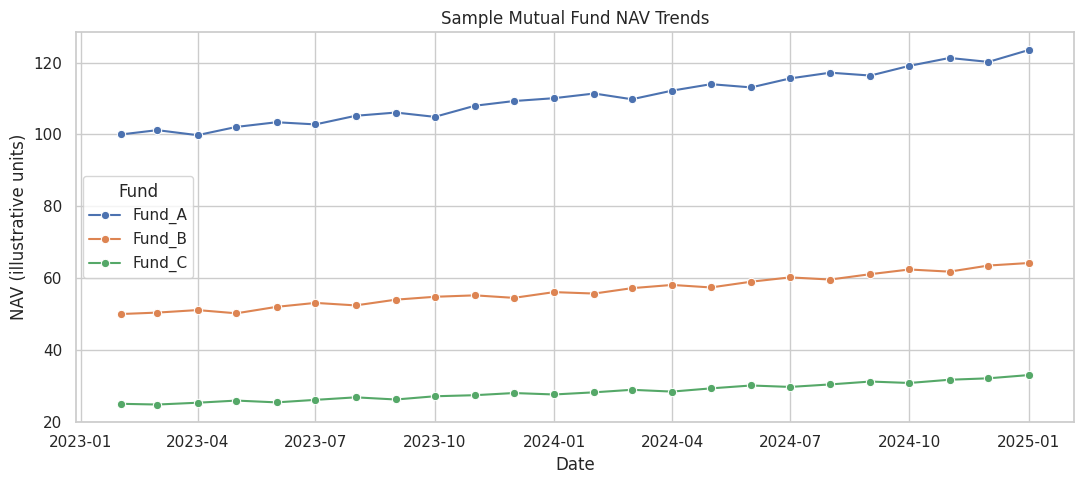

In [ ]:
# Plot 1: NAV trend over time
plt.figure(figsize=(11, 5))
sns.lineplot(data=quality_clean, x="Date", y="NAV", hue="Fund_Name", marker="o")
plt.title("Sample Mutual Fund NAV Trends")
plt.xlabel("Date")
plt.ylabel("NAV (illustrative units)")
plt.legend(title="Fund")
plt.tight_layout()
plt.show()

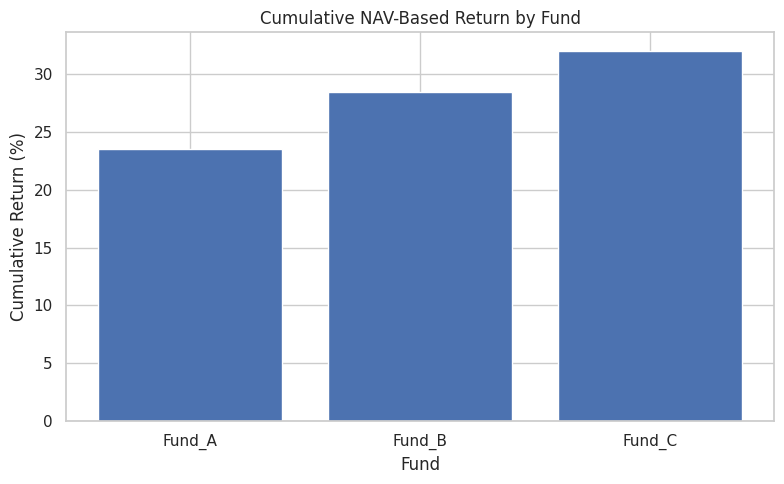

In [ ]:
# Plot 2: Cumulative NAV-based return comparison
plt.figure(figsize=(8, 5))
plt.bar(return_summary["Fund_Name"], return_summary["Cumulative_Return_pct"])
plt.title("Cumulative NAV-Based Return by Fund")
plt.xlabel("Fund")
plt.ylabel("Cumulative Return (%)")
plt.tight_layout()
plt.show()

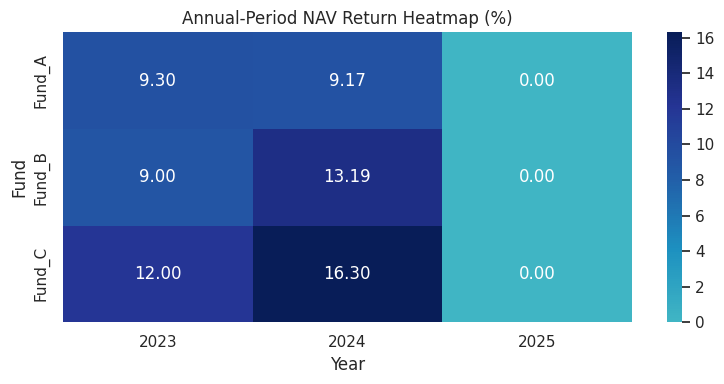

In [ ]:
# Plot 3: Heatmap of annual-period returns
annual_pivot = annual_endpoints.pivot(
    index="Fund_Name",
    columns="Year",
    values="Annual_Period_Return_pct"
)

plt.figure(figsize=(8, 4))
sns.heatmap(annual_pivot, annot=True, fmt=".2f", cmap="YlGnBu", center=0)
plt.title("Annual-Period NAV Return Heatmap (%)")
plt.xlabel("Year")
plt.ylabel("Fund")
plt.tight_layout()
plt.show()

**Conclusion / Insight:** The line plot compares NAV trajectories, the bar chart compares overall NAV-based percentage change, and the heatmap summarizes annual-period changes. Describe the patterns visible in your outputs. Because the dataset is illustrative, these charts do not describe real mutual fund performance.

## Overall conclusion

This project demonstrates how NumPy and Pandas can summarize NAV values, calculate percentage returns, clean tabular data, and group observations by year. Matplotlib and Seaborn are used to visualize NAV trends and return comparisons.

**Write your final findings using the actual notebook outputs:**
1. Which fund has the highest average NAV?
2. Which fund has the highest cumulative NAV-based return over the sample period?
3. Were any missing values, duplicates, or invalid NAV records found?
4. Which fund/year combinations show larger or smaller annual-period NAV changes?
5. What patterns are visible in the line plot, bar chart, and heatmap?

## Limitations
- The data is illustrative, not real market NAV data.
- NAV levels alone do not determine which fund is best.
- The cumulative return calculation is NAV-based and does not include distributions, fees, taxes, or risk adjustment.
- Historical performance does not guarantee future performance.
- Correlation or visual patterns alone do not prove causation.

## Reproducibility and submission checklist
- Keep this notebook and `sample_mutual_fund_performance_analysis.csv` in the same folder/session.
- Run the notebook from top to bottom and confirm that all tables and plots display.
- Submit the `.ipynb` notebook and CSV dataset.
- Upload both files to GitHub and share the repository link as instructed in the sample.
- Submit the project report as a hard copy.
- Fill in your name and roll number on the report cover page before printing.

## Dataset note
Dataset used: `sample_mutual_fund_performance_analysis.csv` — illustrative classroom data generated for this project. No real mutual fund data source is claimed.